# 07. E1: Deteksi AI pada Esai

Tiga detektor dibandingkan pada 10 esai: 5 esai manusia yang ditulis sebelum 2021 dan 5 esai AI dengan topik yang sama.

| Detektor | Cara kerja | Ambang sedang / tinggi |
|---|---|---|
| Heuristik | 5 sinyal gaya tulisan, dihitung lokal | 42 / 70 |
| Groq gpt-oss-120b | LLM menilai esai dengan prompt produksi | 42 / 70 |
| Winston AI | API detektor komersial | 35 / 70 |

Setiap esai dipotong menjadi 100 kata pertama supaya ketiga detektor menilai teks yang sama dan kredit Winston cukup.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import notebook_kit as kit
from src.evaluate_baseline import bootstrap_backend

pd.set_option("display.max_colwidth", 70)

KEYS = kit.use_keys(groq_env="GROQ_API_KEY_E1")
bootstrap_backend()
from apps.analysis.engines.ai_score import score_ai_probability
from apps.analysis.engines.text_features import extract_features
from apps.analysis.providers import groq as groq_judge
from apps.analysis.providers import winston
from src import evaluate_detector, metrics

DATA = ROOT / "data" / "essays" / "essays.csv"
CACHE = ROOT / "data" / "cache" / "e1_esai.jsonl"
OUT = kit.results_dir("e1_esai")

N_PER_CLASS = 5
HUMAN_BEFORE_YEAR = 2021
MAX_WORDS = 100
WINSTON_BUDGET = 2000
GEN_MODELS = ["llama-3.1-8b-instant", "qwen/qwen3-32b", "openai/gpt-oss-20b"]
BANDS = {"heuristik": (42, 70), "groq": (42, 70), "winston": (35, 70)}

Kunci: groq ada, winston ada


## 1. Data

Esai manusia dibaca dari `data/essays/essays.csv`. Esai AI dibuat oleh Groq dengan topik dan panjang yang sama, memakai model yang berbeda dari penilai.

In [2]:
COLUMNS = ["id", "label", "topic", "year", "source", "generator", "prompt", "text"]

if not DATA.exists():
    DATA.parent.mkdir(parents=True, exist_ok=True)
    template = [{"id": f"H{i:02d}", "label": "human"} for i in range(1, N_PER_CLASS + 1)]
    pd.DataFrame(template, columns=COLUMNS).to_csv(DATA, index=False)
    raise SystemExit(f"Template dibuat di {DATA}. Isi 5 esai manusia lalu jalankan ulang.")

essays = pd.read_csv(DATA, dtype=str).fillna("")
essays[["id", "label", "year", "topic"]]

,id,label,year,topic
0,H01,human,2018,Pola pendidikan dengan pendekatan STEAM
1,H02,human,2020,Bekerja di startup teknologi dan talenta yang dibutuhkan
2,H03,human,2016,"Pencemaran lingkungan, pemanasan global, dan peran universitas"
3,H04,human,2020,Proses bisnis dan manfaatnya bagi perusahaan
4,H05,human,2017,"Perbedaan Sistem Komputer, Teknik Informatika, dan Sistem Informasi"


In [3]:
PROMPT = (
    'Tulis esai mahasiswa S1 berbahasa Indonesia sekitar {words} kata berjudul "{topic}". '
    "Langsung tulis isinya dalam beberapa paragraf, tanpa judul, tanpa poin-poin, tanpa kalimat pembuka untuk pembaca."
)


def generate_missing_ai(df):
    humans = df[df.label == "human"]
    todo = humans[~humans.topic.isin(df.loc[df.label == "ai", "topic"])]
    if todo.empty:
        return df
    models = [m for m in GEN_MODELS if m in kit.groq_models()]
    rows = []
    for i, human in enumerate(todo.itertuples()):
        model = models[i % len(models)]
        prompt = PROMPT.format(words=min(len(human.text.split()), MAX_WORDS), topic=human.topic)
        text = kit.with_retry(kit.groq_chat, prompt, model, max_tokens=768)
        rows.append({"id": human.id.replace("H", "A"), "label": "ai", "topic": human.topic, "year": "2026",
                     "source": "Groq", "generator": model, "prompt": prompt, "text": text})
        print(f"{rows[-1]['id']} dari {model}: {len(text.split())} kata")
    df = pd.concat([df, pd.DataFrame(rows)], ignore_index=True)
    df.to_csv(DATA, index=False)
    return df


essays = generate_missing_ai(essays)

A01 dari openai/gpt-oss-20b: 81 kata


A02 dari openai/gpt-oss-20b: 86 kata


A03 dari openai/gpt-oss-20b: 94 kata


A04 dari openai/gpt-oss-20b: 88 kata


A05 dari openai/gpt-oss-20b: 85 kata


In [4]:
humans = essays[essays.label == "human"]
checks = pd.Series({
    "5 esai manusia": len(humans) == N_PER_CLASS,
    "5 esai AI": (essays.label == "ai").sum() == N_PER_CLASS,
    "manusia ditulis sebelum 2021": pd.to_numeric(humans.year, errors="coerce").lt(HUMAN_BEFORE_YEAR).all(),
    "sumber manusia diisi": humans.source.str.strip().ne("").all(),
    "tidak ada teks kosong": essays.text.str.strip().ne("").all(),
    "tidak ada duplikat": not essays.text.duplicated().any(),
    "semua berbahasa Indonesia": essays.text.map(lambda t: extract_features(t).indonesian_ratio >= 0.12).all(),
}, name="lulus")
display(checks)
assert checks.all(), "Perbaiki data sebelum lanjut."

5 esai manusia                  True
5 esai AI                       True
manusia ditulis sebelum 2021    True
sumber manusia diisi            True
tidak ada teks kosong           True
tidak ada duplikat              True
semua berbahasa Indonesia       True
Name: lulus, dtype: bool

## 2. Pra-pemrosesan

Spasi dirapikan dan daftar pustaka dibuang. Lalu setiap esai diambil 100 kata pertamanya. Potongan berhenti di akhir kalimat bila panjangnya masih cukup untuk Winston (minimal 600 karakter).

In [5]:
def clean(text):
    text = re.split(r"\n\s*(daftar pustaka|referensi|references)\b", text, flags=re.I)[0]
    return re.sub(r"\s+", " ", text).strip()


def excerpt(text):
    cut = " ".join(text.split()[:MAX_WORDS])
    ends = [m.end() for m in re.finditer(r"[.!?](?=\s|$)", cut)]
    if ends:
        sentence = cut[: ends[-1]]
        if len(sentence.split()) >= 0.8 * MAX_WORDS and len(sentence) >= winston.RELIABLE_MIN_CHARS:
            return sentence
    return cut


essays["text"] = essays.text.map(clean)
essays["words_asli"] = essays.text.str.split().str.len()
essays["text"] = essays.text.map(excerpt)
essays["words"] = essays.text.str.split().str.len()
essays["chars"] = essays.text.str.len()
essays[["id", "label", "words_asli", "words", "chars"]]

,id,label,words_asli,words,chars
0,H01,human,613,86,658
1,H02,human,745,100,685
2,H03,human,564,87,620
3,H04,human,488,96,772
4,H05,human,355,100,677
5,A01,ai,81,81,663
6,A02,ai,86,86,701
7,A03,ai,94,94,757
8,A04,ai,88,88,769
9,A05,ai,85,85,723


## 3. Pengujian

Setiap potongan esai dinilai ketiga detektor dengan kode produksi. Hasil disimpan di cache supaya jalan ulang tidak memakai kredit lagi. Winston hanya dijalankan bila kredit yang dibutuhkan masih di bawah anggaran.

In [6]:
cache = kit.load_jsonl(CACHE)


def cache_key(name, text):
    return f"{name}:{hashlib.sha256(text.encode()).hexdigest()[:16]}"


def cached(name, text, fn):
    key = cache_key(name, text)
    if key not in cache:
        value, seconds = kit.timed(fn, text)
        cache[key] = {**value, "seconds": round(seconds, 2)}
        kit.append_jsonl(CACHE, key, cache[key])
    return cache[key]


def run_heuristic(text):
    result = score_ai_probability(extract_features(text))
    top = sorted(result.breakdown, key=lambda s: -s.contribution)[:2]
    return {"score": result.score, "reasons": "; ".join(f"{s.label} +{s.contribution}" for s in top)}


def run_groq(text):
    raise RuntimeError("Kolom Groq E1 historis: prompt produksi kini khusus Bloom dan tidak memberi ai_probability. Hasil lama dibaca dari cache.")


def run_winston(text):
    probability = evaluate_detector.fetch_ai_probability(text, os.environ["WINSTON_API_KEY"], winston)
    return {"score": round(probability * 100), "reasons": ""}


DETECTORS = {"heuristik": run_heuristic, "groq": run_groq, "winston": run_winston}
active = {"heuristik": True, "groq": KEYS["groq"], "winston": KEYS["winston"]}

if active["winston"]:
    pending = essays[(essays.chars >= winston.MIN_CHARS) & ~essays.text.map(lambda t: cache_key("winston", t) in cache)]
    credits = int(pending.words.sum())
    print(f"Winston: {len(pending)} esai baru, sekitar {credits} kredit (anggaran {WINSTON_BUDGET})")
    if credits > WINSTON_BUDGET:
        active["winston"] = False
        print("Winston dilewati karena melebihi anggaran.")

records = []
for name, fn in DETECTORS.items():
    if not active[name]:
        print(f"{name}: dilewati")
        continue
    for row in essays.itertuples():
        if name == "winston" and row.chars < winston.MIN_CHARS:
            continue
        try:
            records.append({"id": row.id, "label": row.label, "detector": name, **cached(name, row.text, fn)})
        except SystemExit as stop:
            print(f"{name}: berhenti. {str(stop).strip()[:120]}")
            break


def band(score, detector):
    mid, high = BANDS[detector]
    return "tinggi" if score >= high else "sedang" if score >= mid else "rendah"


scores = pd.DataFrame(records)
scores["band"] = [band(s, d) for s, d in zip(scores.score, scores.detector)]
scores.groupby("detector").size().rename("esai dinilai")

Winston: 10 esai baru, sekitar 903 kredit (anggaran 2000)


detector
groq         10
heuristik    10
winston      10
Name: esai dinilai, dtype: int64

## 4. Hasil

FPR adalah esai manusia yang dituduh AI. TPR adalah esai AI yang tertangkap. Karena tiap kelompok hanya 5 esai, setiap angka diberi interval Wilson 95%.

In [7]:
per_essay = (
    essays.set_index("id")[["label", "words"]]
    .join(scores.pivot(index="id", columns="detector", values="score"))
    .sort_values(["label", "id"])
)
per_essay

,label,words,groq,heuristik,winston
id,,,,,
A01,ai,81,65,48,100
A02,ai,86,60,55,100
A03,ai,94,55,45,99
A04,ai,88,55,55,99
A05,ai,85,58,40,95
H01,human,86,55,48,0
H02,human,100,45,37,0
H03,human,87,65,37,1
H04,human,96,60,39,0


In [8]:
rows = []
for name, group in scores.groupby("detector"):
    y = (group.label == "ai").astype(int).tolist()
    for rule, threshold in (("tinggi", BANDS[name][1]), ("sedang ke atas", BANDS[name][0])):
        r = metrics.confusion_at(group.score.tolist(), y, threshold)
        n_human, n_ai = r.false_positive + r.true_negative, r.true_positive + r.false_negative
        fpr, tpr = kit.wilson(r.false_positive, n_human), kit.wilson(r.true_positive, n_ai)
        rows.append({
            "detektor": name, "aturan": f"{rule} (skor {threshold}+)",
            "FPR": f"{r.false_positive}/{n_human} [{fpr[0]:.0%}-{fpr[1]:.0%}]",
            "TPR": f"{r.true_positive}/{n_ai} [{tpr[0]:.0%}-{tpr[1]:.0%}]",
        })
decision = pd.DataFrame(rows)

overview = scores.groupby("detector").agg(
    auc=("score", lambda s: metrics.roc_auc(s.tolist(), (scores.loc[s.index, "label"] == "ai").astype(int).tolist())),
    detik_median=("seconds", "median"),
).round(3)
display(decision)
overview

,detektor,aturan,FPR,TPR
0,groq,tinggi (skor 70+),0/5 [0%-43%],0/5 [0%-43%]
1,groq,sedang ke atas (skor 42+),4/5 [38%-96%],5/5 [57%-100%]
2,heuristik,tinggi (skor 70+),0/5 [0%-43%],0/5 [0%-43%]
3,heuristik,sedang ke atas (skor 42+),1/5 [4%-62%],4/5 [38%-96%]
4,winston,tinggi (skor 70+),0/5 [0%-43%],5/5 [57%-100%]
5,winston,sedang ke atas (skor 35+),0/5 [0%-43%],5/5 [57%-100%]


,auc,detik_median
detector,,
groq,0.64,20.23
heuristik,0.90,0.00
winston,1.00,1.41


## 5. Perbandingan

Grafik menunjukkan skor tiap esai dan ambang tiap detektor. Tabel di bawahnya berisi esai yang dinilai berbeda oleh para detektor beserta alasannya.

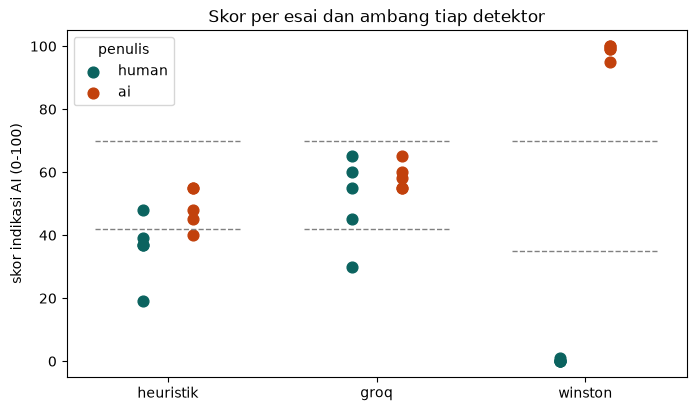

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(scores.detector.unique())
for x, name in enumerate(names):
    group = scores[scores.detector == name]
    for label, color, offset in (("human", "#0B635F", -0.12), ("ai", "#C2410C", 0.12)):
        part = group[group.label == label]
        ax.scatter([x + offset] * len(part), part.score, color=color, s=60, label=label if x == 0 else None)
    for threshold in BANDS[name]:
        ax.hlines(threshold, x - 0.35, x + 0.35, colors="grey", linestyles="dashed", linewidth=1)
ax.set_xticks(range(len(names)), names)
ax.set_ylabel("skor indikasi AI (0-100)")
ax.set_ylim(-5, 105)
ax.legend(title="penulis")
ax.set_title("Skor per esai dan ambang tiap detektor")
kit.save_figure(fig, "e1_skor_per_detektor.png")
plt.show()

In [10]:
bands = scores.pivot(index="id", columns="detector", values="band")
reasons = scores.pivot(index="id", columns="detector", values="reasons")
disagree = bands[bands.nunique(axis=1) > 1]
print(f"{len(bands) - len(disagree)} dari {len(bands)} esai mendapat band yang sama dari semua detektor.")
disagree.join(reasons.add_suffix(" (alasan)")).join(essays.set_index("id").label)

1 dari 10 esai mendapat band yang sama dari semua detektor.


,groq,heuristik,winston,groq (alasan),heuristik (alasan),winston (alasan),label
id,,,,,,,
A01,sedang,sedang,tinggi,panjang kalimat seragam tanpa variasi; tidak ada contoh konkret; t...,Keseragaman kalimat +27.1; Keragaman kosakata +12.5,,ai
A02,sedang,sedang,tinggi,tidak ada contoh konkret; kalimat seragam tanpa variasi panjang; t...,Keseragaman kalimat +32.9; Keragaman kosakata +12.5,,ai
A03,sedang,sedang,tinggi,tidak ada contoh konkret; kalimat panjang seragam tanpa variasi; t...,Keseragaman kalimat +22.2; Keragaman kosakata +12.5,,ai
A04,sedang,sedang,tinggi,tidak ada contoh konkret; tidak ada referensi spesifik; kalimat pa...,Keseragaman kalimat +32.6; Keragaman kosakata +12.5,,ai
A05,sedang,rendah,tinggi,panjang kalimat seragam tanpa variasi; tidak ada contoh konkret; t...,Keseragaman kalimat +18.0; Keragaman kosakata +12.5,,ai
H01,sedang,sedang,rendah,tidak ada contoh konkret; kalimat panjang dan seragam tanpa varias...,Keseragaman kalimat +25.7; Keragaman kosakata +12.5,,human
H02,sedang,rendah,rendah,tidak ada contoh konkret dari pengalaman pribadi; kalimat bersifat...,Keseragaman kalimat +23.3; Keragaman kosakata +12.5,,human
H03,sedang,rendah,rendah,tidak ada contoh konkret; kalimat panjang seragam tanpa variasi; t...,Keseragaman kalimat +14.2; Keragaman kosakata +12.5,,human
H04,sedang,rendah,rendah,tidak ada contoh konkret; kalimat panjang seragam tanpa variasi; t...,Keseragaman kalimat +16.2; Keragaman kosakata +12.5,,human


## 6. Kesimpulan

Ringkasan disimpan ke `results/e1_esai/`. Berkas CSV hanya berisi id dan angka, tanpa teks esai.

In [11]:
per_essay.to_csv(OUT / "per_esai.csv")
decision.to_csv(OUT / "aturan_keputusan.csv", index=False)

kit.write_summary(OUT / "ringkasan.md", "E1: tiga detektor pada 10 esai", {
    "Data": f"{N_PER_CLASS} esai manusia (sebelum {HUMAN_BEFORE_YEAR}) dan {N_PER_CLASS} esai AI dengan topik yang sama, "
            f"masing-masing dipotong menjadi {MAX_WORDS} kata pertama. "
            f"Generator AI: {', '.join(sorted(set(essays.loc[essays.label == 'ai', 'generator'])))}.",
    "Aturan keputusan": kit.md_table(decision),
    "AUC dan waktu": kit.md_table(overview),
    "Batasan": "- Hanya 10 esai, jadi ini studi kasus, bukan akurasi umum.\n"
               "- Ambang 42/70 untuk Groq dipinjam dari heuristik, belum dikalibrasi.\n"
               f"- Yang diuji hanya potongan {MAX_WORDS} kata, bukan esai utuh.",
})
print((OUT / "ringkasan.md").read_text())

# E1: tiga detektor pada 10 esai

## Data

5 esai manusia (sebelum 2021) dan 5 esai AI dengan topik yang sama, masing-masing dipotong menjadi 100 kata pertama. Generator AI: openai/gpt-oss-20b.

## Aturan keputusan

| detektor | aturan | FPR | TPR |
|---|---|---|---|
| groq | tinggi (skor 70+) | 0/5 [0%-43%] | 0/5 [0%-43%] |
| groq | sedang ke atas (skor 42+) | 4/5 [38%-96%] | 5/5 [57%-100%] |
| heuristik | tinggi (skor 70+) | 0/5 [0%-43%] | 0/5 [0%-43%] |
| heuristik | sedang ke atas (skor 42+) | 1/5 [4%-62%] | 4/5 [38%-96%] |
| winston | tinggi (skor 70+) | 0/5 [0%-43%] | 5/5 [57%-100%] |
| winston | sedang ke atas (skor 35+) | 0/5 [0%-43%] | 5/5 [57%-100%] |

## AUC dan waktu

| detector | auc | detik_median |
|---|---|---|
| groq | 0.64 | 20.23 |
| heuristik | 0.9 | 0.0 |
| winston | 1.0 | 1.41 |

## Batasan

- Hanya 10 esai, jadi ini studi kasus, bukan akurasi umum.
- Ambang 42/70 untuk Groq dipinjam dari heuristik, belum dikalibrasi.
- Yang diuji hanya potongan 100 kata, bukan es